<h1  style="color:#000000; text-align:center; font-weight:bold;">DATASCI 530 Assignment 5</h1>
<h1  style="color:#000000; text-align:center; font-weight:bold;">Predicting Class Labels for Iris Flowers</h1>
<p  style="color:#000000; text-align:center; font-size:18px;">Maxine Hakimi-Bulson</p>

<h2 style="color:#000000;">Predicting the Class Label</h2>

write a couple sentences about Topic here

<h2 style="color:#000000;">Summary of Findings</h2>

write summary of findings here in a bulleted list like this:

Here are the main findings:

- 1

- 2

- 3

- 4

- 5

<h2 style="color:#000000;">Loading Libraries and Data</h2>

First we will load the necessary libraries and data to complete our analyses.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf

from sklearn.model_selection import (
    StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB

from tensorflow import keras
from keras.layers import Dense

In [27]:
# Load the Iris dataset and assign column names since
# they currently don't have column names
iris = pd.read_csv(
    "data/iris/iris.data",
    header=None,
    names=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width",
        "class"
    ]
)

<h2 style="color:#000000;">Inquiry & Analysis</h2>

<h3 style="color:#000000;"> 1. Description of Dataset: How many rows? How many features? What is the proportion of observations in each class? </h3>

All of the descriptive statistics of the dataset can be found using Data Wrangler. I made a table showing the number of observations and proportions of each class.

In [28]:
# Count observations and calculate the proportion in each class
table_classes = pd.DataFrame({
    "Number of Observations": iris["class"].value_counts()
})

table_classes["Proportion"] = (
    table_classes["Number of Observations"] / len(iris)
)

# Turn the class names into a regular column
table_classes = table_classes.reset_index()
table_classes = table_classes.rename(columns={"class": "Class"})

# Display the formatted table
display(
    table_classes.style
    .format({"Proportion": "{:.1%}"})
    .hide(axis="index")
    .set_caption("Distribution of Iris Classes")
)

Class,Number of Observations,Proportion
Iris-setosa,50,33.3%
Iris-versicolor,50,33.3%
Iris-virginica,50,33.3%


There are 150 rows, four continuous features, and three categorical labels for iris classification: "Iris-setosa," "Iris-versicolor," and "Iris-virginica." Each class has 50 observations, representing one third of the total observations in this dataset.

<h3 style="color:#000000;"> 2. Run a comparison of different machine learning methods, which should include support vector machines (SVMs), random forests, neural networks, and at least one method we have not covered in class (lasso, naive bayes, ridge, etc.) </h3>

- Evaluate the predictive performance using cross-validation. Consider more than one evaluation metric.
- Use the default tuning parameters for all methods except one (you choose). For this method, define a grid of tuning parameters and select the best-performing ones.

I used the four flower measurements to predict iris species and compared a support vector machine (SVM), random forest, neural network, and Naive Bayes classifier. Naive Bayes was the additional method not covered in class. I evaluated each method using the same five stratified cross-validation folds and calculated average accuracy and macro F1 across the validation folds.

I used the default tuning parameters for the random forest, neural network, and Naive Bayes models. For the SVM, I used a grid search to select C and gamma values based on accuracy within each training fold. I standardized the predictors for the SVM and neural network using the training data for each fold. Finally, I ran the SVM grid search on the full dataset to select a final set of parameters, which were C = 10 and gamma = 0.1.

In [32]:
# Define the predictors and outcome
X = iris.drop(columns="class")
y = iris["class"]

# Use five stratified folds so each fold has similar class proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Define the SVM and scale its predictors
svm = make_pipeline(
    StandardScaler(),
    SVC()
)

# Define a grid of SVM parameters to compare
param_grid = {
    "svc__C": [0.1, 1, 10],
    "svc__gamma": ["scale", 0.01, 0.1]
}

# Tune the SVM using three-fold cross-validation within training data
svm_tuned = GridSearchCV(
    svm,
    param_grid,
    scoring="accuracy",
    cv=3
)

# Define the other models using default tuning parameters
random_forest = RandomForestClassifier(random_state=0)

neural_network = make_pipeline(
    StandardScaler(),
    MLPClassifier(max_iter = 200, random_state=0)
)

naive_bayes = GaussianNB()

# Store the four methods
models = {
    "SVM (tuned)": svm_tuned,
    "Random Forest": random_forest,
    "Neural Network": neural_network,
    "Naive Bayes": naive_bayes
}

# Evaluate every method on the same five folds
model_results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        scoring=["accuracy", "f1_macro"],
        cv=cv,
        error_score="raise"
    )

    # Average the scores across the five validation folds
    model_results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro F1": scores["test_f1_macro"].mean()
    })

# Create and display the comparison table
table_models = (
    pd.DataFrame(model_results)
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(
    table_models.style
    .format({
        "Accuracy": "{:.1%}",
        "Macro F1": "{:.3f}"
    })
    .hide(axis="index")
    .set_caption("Five-Fold Cross-Validation Results by Model")
)

# Select one final set of SVM parameters using the full dataset
final_svm_grid = GridSearchCV(
    svm,
    param_grid,
    scoring="accuracy",
    cv=3
)

final_svm_grid.fit(X, y)

# Display the selected SVM parameters
table_svm_parameters = pd.DataFrame({
    "Parameter": ["C", "Gamma"],
    "Selected Value": [
        str(final_svm_grid.best_params_["svc__C"]),
        str(final_svm_grid.best_params_["svc__gamma"])
    ]
})

display(
    table_svm_parameters.style
    .hide(axis="index")
    .set_caption("Final SVM Parameters Selected Using All Observations")
)

/opt/anaconda3/envs/assignment5/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/assignment5/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/assignment5/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/assignment5/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Model,Accuracy,Macro F1
Naive Bayes,96.0%,0.960
SVM (tuned),95.3%,0.953
Neural Network,94.7%,0.947
Random Forest,94.0%,0.939


Parameter,Selected Value
C,10
Gamma,0.1


Naive Bayes had the highest average accuracy (96.0%) and macro F1 score (0.960), followed closely by the tuned SVM (95.3% and 0.953). The neural network and random forest also performed well, although the neural network reached its default iteration limit before converging in some folds. The final SVM grid search selected C = 10 and gamma = 0.1 from the values tested. Based on this comparison, I would recommend Naive Bayes, although its advantage over the SVM was small and these results are based on a relatively small dataset.

Note: The neural network reached its default limit of 200 iterations before converging in some folds, so its performance may change with additional training.

CHECK IF I CAN CHANGE MLP CLASSIFIER TO DEVIATE FROM DEFAULT SETTINGS AND ADD MAX_ITER = 1000 SO I DONT GET THE WARNINGS: "For Assignment 5, I used the default MLPClassifier settings for the neural network and tuned the SVM. During cross-validation, the neural network produced a convergence warning because it reached the default limit of 200 iterations. When I tried increasing max_iter to 1,000, the warning disappeared and the model’s average accuracy changed slightly.Would it be acceptable to use max_iter=1000 to give the neural network more time to converge, or would you prefer that I keep the default and discuss the warning as a limitation?"

<h2 style="color:#000000;">New Insights</h2>

<h3 style="color:#000000;"> 3. Do the classification methods tend to make mistakes on the same iris flowers? </h3>

I used cross-validation to obtain a predicted species for each flower from each model. For each pair of models, I compared the flowers they classified incorrectly using Jaccard similarity: the number of flowers both models misclassified divided by the number misclassified by at least one of them. I displayed the similarities in a heatmap, where values closer to 1 indicate greater overlap in errors.

/opt/anaconda3/envs/assignment5/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/assignment5/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/assignment5/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/assignment5/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


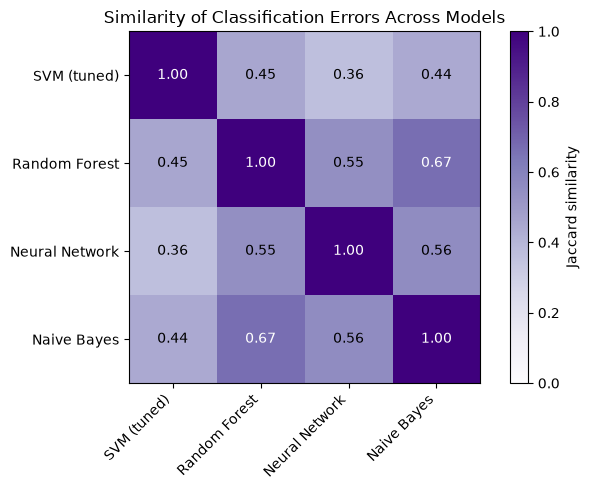

In [33]:
from sklearn.model_selection import cross_val_predict

# Obtain cross-validated predictions for each model
model_predictions = {}

for model_name, model in models.items():
    model_predictions[model_name] = cross_val_predict(
        model,
        X,
        y,
        cv=cv
    )

# Identify which flowers each model classified incorrectly
model_errors = {}

for model_name, predictions in model_predictions.items():
    model_errors[model_name] = predictions != y.to_numpy()

# Create an empty table for pairwise Jaccard similarities
model_names = list(models.keys())

jaccard_table = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

# Compare the sets of misclassified flowers for each pair of models
for model_1 in model_names:
    for model_2 in model_names:
        errors_1 = model_errors[model_1]
        errors_2 = model_errors[model_2]

        # Flowers both models got wrong
        shared_errors = (errors_1 & errors_2).sum()

        # Flowers at least one model got wrong
        either_error = (errors_1 | errors_2).sum()

        # Jaccard similarity; undefined if neither model made an error
        if either_error > 0:
            jaccard_table.loc[model_1, model_2] = (
                shared_errors / either_error
            )
        else:
            jaccard_table.loc[model_1, model_2] = np.nan

# Plot the similarity matrix
fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(jaccard_table, cmap="Purples", vmin=0, vmax=1)

# Label rows and columns
ax.set_xticks(range(len(model_names)))
ax.set_xticklabels(model_names, rotation=45, ha="right")
ax.set_yticks(range(len(model_names)))
ax.set_yticklabels(model_names)

# Add each similarity value to its cell
for row in range(len(model_names)):
    for col in range(len(model_names)):
        value = jaccard_table.iloc[row, col]

        if pd.notna(value):
            ax.text(
                col, row, f"{value:.2f}",
                ha="center", va="center",
                color="white" if value > 0.6 else "black"
            )

ax.set_title("Similarity of Classification Errors Across Models")
fig.colorbar(image, ax=ax, label="Jaccard similarity")
plt.tight_layout()
plt.show()

<h3 style="color:#000000;"> 4. What do we learn from this new table or figure?  </h3>

Although the tuned SVM and neural network both achieved 95.3% accuracy, their Jaccard similarity was only 0.40. This means that, among the flowers misclassified by at least one of those models, 40% were misclassified by both. The random forest and Naive Bayes had the greatest overlap in errors, with a similarity of 0.67. These results show that similar overall accuracy does not necessarily mean that models make mistakes on the same observations. Because the models made relatively few errors, the similarities may be sensitive to a small change in the number of misclassified flowers.

<h2 style="color:#000000;">Final Recommendation</h2>

Make sure to properly document your approach. Give a recommendation about which method
you think predicts the class labels best.